# Week 5: Analytics Report & Insights Documentation
## Customer Churn Analytics using Python

**Internship:** Yuva  
**Goal:** Analyze customer churn, communicate findings with charts, and recommend data-informed retention actions.

### Learning objectives
1. Define the business problem and stakeholders' questions.
2. Analyze the customer dataset and calculate key performance indicators (KPIs).
3. Create meaningful visualizations.
4. Translate findings into business insights.
5. Produce an executive summary.
6. Recommend prioritized actions and measurable next steps.

> **Data note:** This project uses the supplied synthetic telecom churn dataset. Findings demonstrate an analysis method and are not real results from a telecom company. Keep this notebook and `synthetic_telco_churn.csv` in the same folder before running it.

## 1. Define the business objective

**Business problem:** A subscription telecom provider wants to understand which customer groups are more likely to leave and where retention efforts should focus.

**Stakeholders:** Customer Retention, Marketing, Product, Billing/Finance, and Data teams.

**Questions to answer:**
- What is the overall churn rate and the monthly recurring charges associated with churned customers?
- How does churn differ by contract, tenure, internet service, payment method, and tech support?
- Which customer segments may deserve retention attention first?
- What actions should be tested, and how will success be measured?

**Success metrics:** Overall churn rate, monthly charges associated with churn, 6-month customer retention, share of customers on contracts of 12 months or longer, and performance of retention tests.

In [1]:
# 2. Import libraries and configure display
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 120)
sns.set_theme(style="whitegrid")

print("Python:", sys.version.split()[0])
print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("Seaborn:", sns.__version__)

Python: 3.13.5
Pandas: 2.2.3
NumPy: 2.3.5
Seaborn: 0.13.2


In [2]:
# 3. Load the supplied CSV file
possible_paths = [
    Path("synthetic_telco_churn.csv"),
    Path("data") / "synthetic_telco_churn.csv",
    Path("/mnt/data/synthetic_telco_churn.csv"),  # fallback for this workspace
]
csv_path = next((path for path in possible_paths if path.exists()), None)
if csv_path is None:
    raise FileNotFoundError(
        "Could not find synthetic_telco_churn.csv. Put the CSV in the same folder as this notebook and rerun this cell."
    )

df = pd.read_csv(csv_path)
print(f"Loaded file: {csv_path}")
print(f"Rows: {df.shape[0]:,} | Columns: {df.shape[1]}")
display(df.head())

Loaded file: synthetic_telco_churn.csv
Rows: 7,043 | Columns: 10


,customerID,SeniorCitizen,tenure,Contract,InternetService,TechSupport,PaymentMethod,MonthlyCharges,Churn,TotalCharges
0,C00000,0,33,Two year,Fiber optic,No,Electronic check,82.51,Yes,2722.83
1,C00001,0,2,Month-to-month,No,No internet service,Electronic check,24.74,Yes,49.48
2,C00002,0,64,Two year,No,No internet service,Mailed check,18.25,No,1168.00
3,C00003,0,58,One year,Fiber optic,Yes,Electronic check,61.71,No,3579.18
4,C00004,0,35,Month-to-month,Fiber optic,No,Mailed check,75.90,Yes,2656.50


## 2. Understand and check the data

The dataset includes a customer identifier, tenure, contract type, internet service, tech support, payment method, monthly and total charges, senior-citizen indicator, and churn outcome. The customer identifier is useful for record checking but should not be treated as a predictive business feature.

In [3]:
# Inspect column types, summary statistics, missing values and duplicate records
print("Column data types:")
display(df.dtypes.rename("data_type").to_frame())
print("Missing values per column:")
display(df.isna().sum().rename("missing_count").to_frame())
print("Duplicate rows:", int(df.duplicated().sum()))
if "customerID" in df.columns:
    print("Duplicate customer IDs:", int(df["customerID"].duplicated().sum()))
print("Numeric summary:")
display(df.select_dtypes(include=np.number).describe().T)

Column data types:


,data_type
customerID,object
SeniorCitizen,int64
tenure,int64
Contract,object
InternetService,object
TechSupport,object
PaymentMethod,object
MonthlyCharges,float64
Churn,object
TotalCharges,float64


Missing values per column:


,missing_count
customerID,0
SeniorCitizen,0
tenure,0
Contract,0
InternetService,0
TechSupport,0
PaymentMethod,0
MonthlyCharges,0
Churn,0
TotalCharges,0


Duplicate rows: 0
Duplicate customer IDs: 0
Numeric summary:


,count,mean,std,min,25%,50%,75%,max
SeniorCitizen,7043.0,0.153486,0.360481,0.00,0.000,0.00,0.00,1.00
tenure,7043.0,26.265796,17.427891,1.00,12.000,23.00,37.00,72.00
MonthlyCharges,7043.0,56.535164,25.039272,18.25,36.050,52.52,80.56,109.97
TotalCharges,7043.0,1475.638715,1243.572270,18.25,538.075,1116.72,2119.48,7457.84


In [4]:
# Validate required columns and create an analysis-friendly churn indicator
required = ["tenure", "Contract", "InternetService", "TechSupport", "PaymentMethod",
            "MonthlyCharges", "Churn"]
missing_required = [col for col in required if col not in df.columns]
if missing_required:
    raise ValueError(f"The CSV is missing required columns: {missing_required}")

df["Churn"] = df["Churn"].astype(str).str.strip()
if not set(df["Churn"].dropna().unique()).issubset({"Yes", "No"}):
    raise ValueError("Expected Churn values to be 'Yes' or 'No'. Check the source data.")
df["ChurnFlag"] = (df["Churn"] == "Yes").astype(int)
print("Churn values:", df["Churn"].value_counts().to_dict())
print("Analysis-ready dataset shape:", df.shape)

Churn values: {'No': 4843, 'Yes': 2200}
Analysis-ready dataset shape: (7043, 11)


## 3. Calculate headline business KPIs

For this analysis, the **churn rate** is the fraction of customers with `Churn = Yes`. The **monthly charges associated with churn** is the sum of `MonthlyCharges` for churned customers; it is an estimate of monthly recurring charges at risk, not a complete accounting measure of realized revenue loss.

In [5]:
total_customers = len(df)
churned_customers = int(df["ChurnFlag"].sum())
overall_churn_rate = df["ChurnFlag"].mean()
avg_monthly_charge = df["MonthlyCharges"].mean()
monthly_charges_at_risk = df.loc[df["ChurnFlag"] == 1, "MonthlyCharges"].sum()
monthly_charges_all = df["MonthlyCharges"].sum()
churn_charge_share = monthly_charges_at_risk / monthly_charges_all if monthly_charges_all else np.nan

kpi = pd.DataFrame({
    "Metric": ["Customers analyzed", "Customers churned", "Overall churn rate",
               "Average monthly charge", "Monthly charges associated with churn",
               "Share of monthly charges associated with churn"],
    "Value": [f"{total_customers:,}", f"{churned_customers:,}", f"{overall_churn_rate:.1%}",
              f"${avg_monthly_charge:,.2f}", f"${monthly_charges_at_risk:,.2f}", f"{churn_charge_share:.1%}"]
})
display(kpi)

print("Average tenure by churn status (months):")
display(df.groupby("Churn")["tenure"].mean().round(1).rename("Average tenure (months)").to_frame())
print("Average monthly charge by churn status:")
display(df.groupby("Churn")["MonthlyCharges"].mean().round(2).rename("Average monthly charge ($)").to_frame())

,Metric,Value
0,Customers analyzed,"7,043"
1,Customers churned,"2,200"
2,Overall churn rate,31.2%
3,Average monthly charge,$56.54
4,Monthly charges associated with churn,"$139,162.46"
5,Share of monthly charges associated with churn,34.9%


Average tenure by churn status (months):


,Average tenure (months)
Churn,
No,30.5
Yes,16.9


Average monthly charge by churn status:


,Average monthly charge ($)
Churn,
No,53.48
Yes,63.26


## 4. Analyze churn by customer segment

The following reusable function reports segment size, churn rate, number of churned customers, and each segment's share of all churn. These measures answer different questions: a high churn rate describes risk within a group, while share of churn describes that group's contribution to all churned customers.

In [6]:
def segment_summary(data, column):
    summary = data.groupby(column, dropna=False).agg(
        customers=("ChurnFlag", "size"),
        churned_customers=("ChurnFlag", "sum"),
        churn_rate=("ChurnFlag", "mean"),
        monthly_charges_at_risk=("MonthlyCharges", lambda x: x[data.loc[x.index, "ChurnFlag"] == 1].sum()),
    )
    summary["share_of_all_churn"] = summary["churned_customers"] / max(data["ChurnFlag"].sum(), 1)
    return summary.sort_values("churn_rate", ascending=False)

for column in ["Contract", "InternetService", "PaymentMethod"]:
    print(f"\n{column}:")
    display(segment_summary(df, column).style.format({
        "churn_rate": "{:.1%}",
        "share_of_all_churn": "{:.1%}",
        "monthly_charges_at_risk": "${:,.2f}"
    }))


Contract:


,customers,churned_customers,churn_rate,monthly_charges_at_risk,share_of_all_churn
Contract,,,,,
Month-to-month,3921,1893,48.3%,"$119,383.99",86.0%
One year,1480,232,15.7%,"$15,266.16",10.5%
Two year,1642,75,4.6%,"$4,512.31",3.4%



InternetService:


,customers,churned_customers,churn_rate,monthly_charges_at_risk,share_of_all_churn
InternetService,,,,,
Fiber optic,3121,1252,40.1%,"$102,698.84",56.9%
DSL,2407,665,27.6%,"$29,980.36",30.2%
No,1515,283,18.7%,"$6,483.26",12.9%



PaymentMethod:


,customers,churned_customers,churn_rate,monthly_charges_at_risk,share_of_all_churn
PaymentMethod,,,,,
Electronic check,2369,869,36.7%,"$54,817.31",39.5%
Bank transfer,1586,465,29.3%,"$29,864.40",21.1%
Credit card,1560,447,28.7%,"$27,679.89",20.3%
Mailed check,1528,419,27.4%,"$26,800.86",19.0%


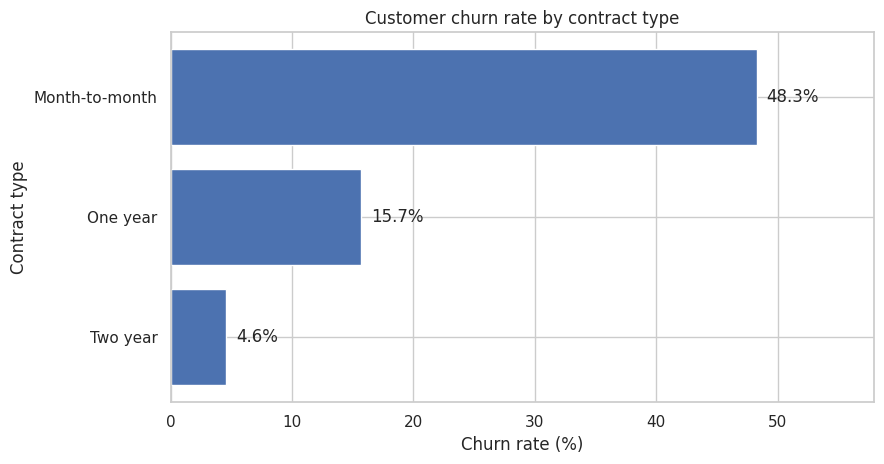

In [7]:
# Visualization 1: Churn rate by contract type
contract_summary = segment_summary(df, "Contract").sort_values("churn_rate", ascending=True)
fig, ax = plt.subplots(figsize=(9, 4.8))
ax.barh(contract_summary.index.astype(str), contract_summary["churn_rate"] * 100)
ax.set_title("Customer churn rate by contract type")
ax.set_xlabel("Churn rate (%)")
ax.set_ylabel("Contract type")
for i, val in enumerate(contract_summary["churn_rate"] * 100):
    ax.text(val + 0.8, i, f"{val:.1f}%", va="center")
ax.set_xlim(0, max(contract_summary["churn_rate"] * 100) * 1.2)
plt.tight_layout()
plt.show()

,customers,churned_customers,churn_rate
TenureBand,,,
0–6,830,479,57.7%
7–12,976,463,47.4%
13–24,1847,697,37.7%
25–48,2447,524,21.4%
49+,943,37,3.9%


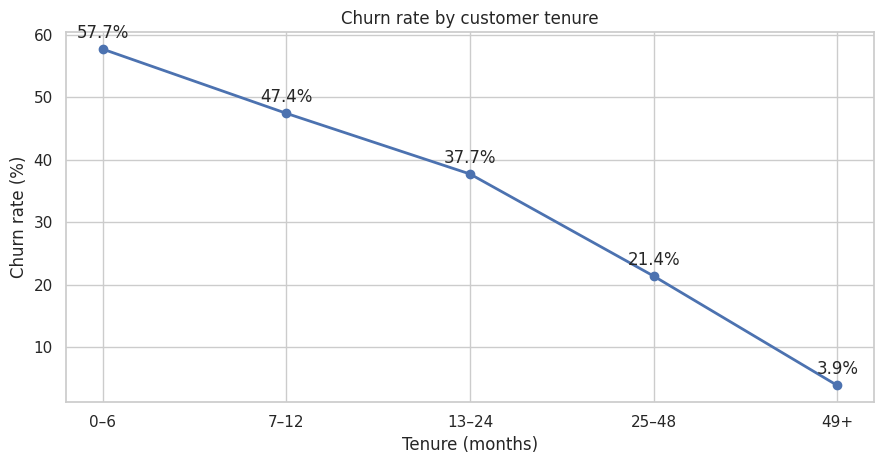

In [8]:
# Visualization 2: Churn across tenure bands
tenure_bins = [-1, 6, 12, 24, 48, np.inf]
tenure_labels = ["0–6", "7–12", "13–24", "25–48", "49+"]
df["TenureBand"] = pd.cut(df["tenure"], bins=tenure_bins, labels=tenure_labels)
tenure_summary = df.groupby("TenureBand", observed=False).agg(
    customers=("ChurnFlag", "size"),
    churned_customers=("ChurnFlag", "sum"),
    churn_rate=("ChurnFlag", "mean")
)
display(tenure_summary.style.format({"churn_rate": "{:.1%}"}))
fig, ax = plt.subplots(figsize=(9, 4.8))
ax.plot(tenure_summary.index.astype(str), tenure_summary["churn_rate"] * 100, marker="o", linewidth=2)
ax.set_title("Churn rate by customer tenure")
ax.set_xlabel("Tenure (months)")
ax.set_ylabel("Churn rate (%)")
for i, val in enumerate(tenure_summary["churn_rate"] * 100):
    ax.annotate(f"{val:.1f}%", (i, val), textcoords="offset points", xytext=(0, 8), ha="center")
plt.tight_layout()
plt.show()

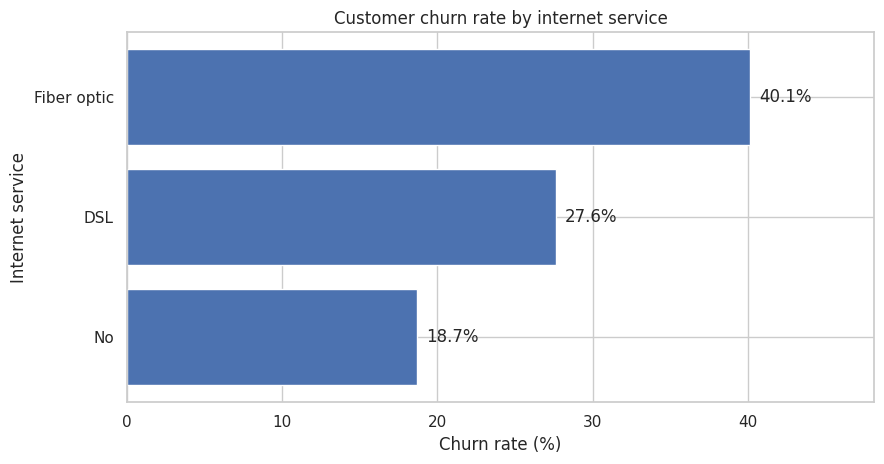

In [9]:
# Visualization 3: Churn by internet service
internet_summary = segment_summary(df, "InternetService").sort_values("churn_rate", ascending=True)
fig, ax = plt.subplots(figsize=(9, 4.8))
ax.barh(internet_summary.index.astype(str), internet_summary["churn_rate"] * 100)
ax.set_title("Customer churn rate by internet service")
ax.set_xlabel("Churn rate (%)")
ax.set_ylabel("Internet service")
for i, val in enumerate(internet_summary["churn_rate"] * 100):
    ax.text(val + 0.6, i, f"{val:.1f}%", va="center")
ax.set_xlim(0, max(internet_summary["churn_rate"] * 100) * 1.2)
plt.tight_layout()
plt.show()

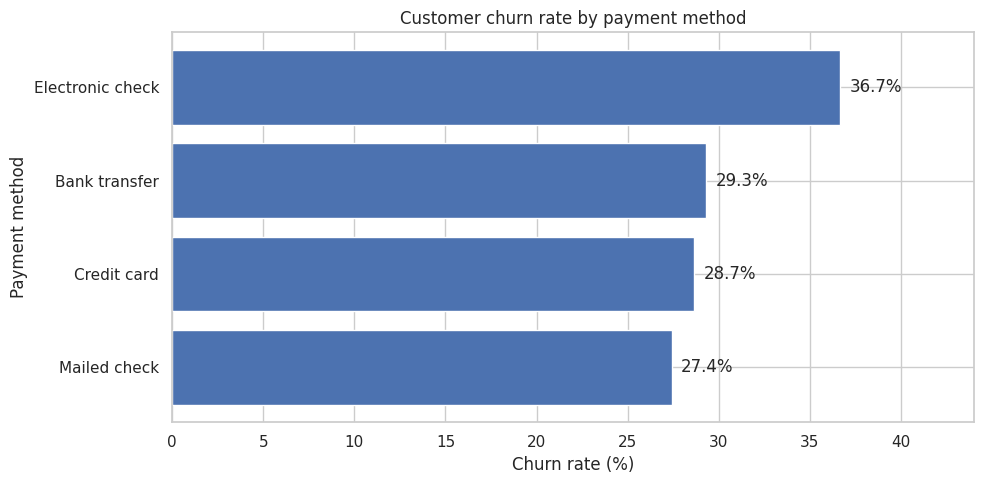

In [10]:
# Visualization 4: Churn by payment method
payment_summary = segment_summary(df, "PaymentMethod").sort_values("churn_rate", ascending=True)
fig, ax = plt.subplots(figsize=(10, 5))
ax.barh(payment_summary.index.astype(str), payment_summary["churn_rate"] * 100)
ax.set_title("Customer churn rate by payment method")
ax.set_xlabel("Churn rate (%)")
ax.set_ylabel("Payment method")
for i, val in enumerate(payment_summary["churn_rate"] * 100):
    ax.text(val + 0.5, i, f"{val:.1f}%", va="center")
ax.set_xlim(0, max(payment_summary["churn_rate"] * 100) * 1.2)
plt.tight_layout()
plt.show()

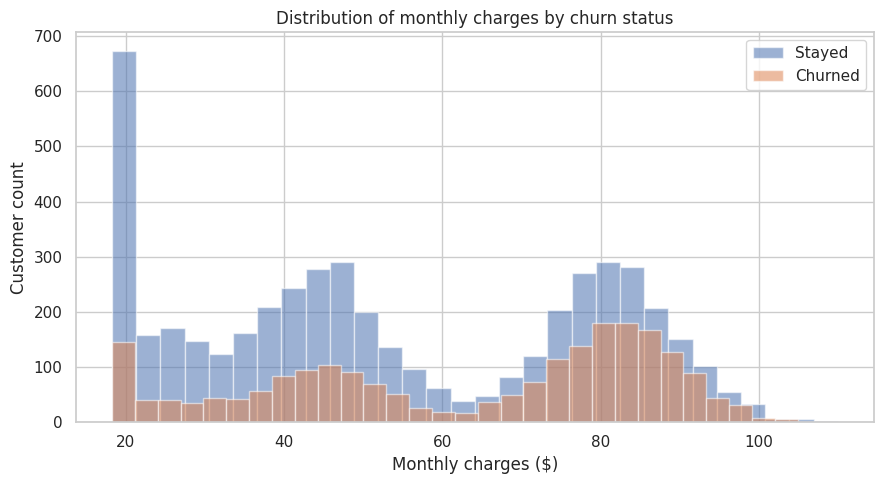

In [11]:
# Visualization 5: Monthly charges for customers who stayed vs churned
fig, ax = plt.subplots(figsize=(9, 5))
for label in ["No", "Yes"]:
    values = df.loc[df["Churn"] == label, "MonthlyCharges"]
    ax.hist(values, bins=30, alpha=0.55, label=("Stayed" if label == "No" else "Churned"))
ax.set_title("Distribution of monthly charges by churn status")
ax.set_xlabel("Monthly charges ($)")
ax.set_ylabel("Customer count")
ax.legend()
plt.tight_layout()
plt.show()

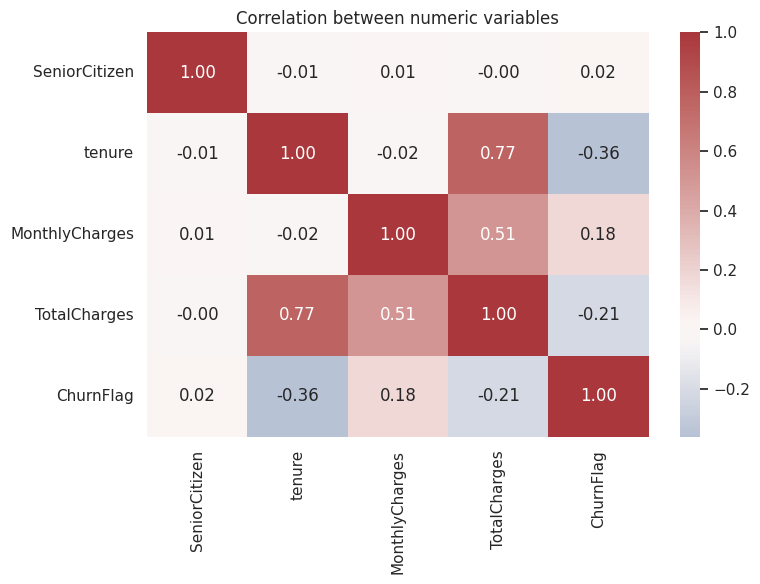

In [12]:
# Visualization 6: Numeric correlation heatmap
numeric_cols = [col for col in ["SeniorCitizen", "tenure", "MonthlyCharges", "TotalCharges", "ChurnFlag"] if col in df.columns]
corr = df[numeric_cols].corr(numeric_only=True)
fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="vlag", center=0, ax=ax)
ax.set_title("Correlation between numeric variables")
plt.tight_layout()
plt.show()

## 5. Examine the high-risk segment and tech support

The report focuses on month-to-month fiber customers without tech support. The next cell calculates its size, churn rate, contribution to all churn, and the monthly charges associated with its churned customers directly from the supplied dataset. It also compares tech-support groups among internet customers.

In [13]:
internet_customers = df[df["InternetService"] != "No"]
tech_support_summary = internet_customers.groupby("TechSupport").agg(
    customers=("ChurnFlag", "size"),
    churned_customers=("ChurnFlag", "sum"),
    churn_rate=("ChurnFlag", "mean")
)
display(tech_support_summary.style.format({"churn_rate": "{:.1%}"}))

high_risk = df[
    (df["Contract"] == "Month-to-month") &
    (df["InternetService"] == "Fiber optic") &
    (df["TechSupport"] == "No")
]
high_risk_churners = high_risk[high_risk["ChurnFlag"] == 1]
high_risk_stats = pd.DataFrame({
    "Metric": ["Customers in high-risk segment", "Churned customers in segment",
               "Segment churn rate", "Share of all churned customers",
               "Monthly charges associated with segment churn"],
    "Value": [f"{len(high_risk):,}", f"{len(high_risk_churners):,}",
              f"{high_risk['ChurnFlag'].mean():.1%}",
              f"{len(high_risk_churners) / max(churned_customers, 1):.1%}",
              f"${high_risk_churners['MonthlyCharges'].sum():,.2f}"]
})
display(high_risk_stats)

,customers,churned_customers,churn_rate
TechSupport,,,
No,3839,1462,38.1%
Yes,1689,455,26.9%


,Metric,Value
0,Customers in high-risk segment,"1,229"
1,Churned customers in segment,803
2,Segment churn rate,65.3%
3,Share of all churned customers,36.5%
4,Monthly charges associated with segment churn,"$65,780.82"


## 6. Business insights

Use the data-backed results below as a concise interpretation. These are associations observed in a synthetic dataset; they do not prove the causes of churn.

In [14]:
# Generate a small table of the most relevant data-backed findings
contract_rate = df.groupby("Contract")["ChurnFlag"].mean()
tenure_rate = tenure_summary["churn_rate"]
internet_rate = df.groupby("InternetService")["ChurnFlag"].mean()
payment_rate = df.groupby("PaymentMethod")["ChurnFlag"].mean()

insights = pd.DataFrame([
    {"Finding": "Contract type", "Evidence": f"Month-to-month churn is {contract_rate.get('Month-to-month', np.nan):.1%}; two-year churn is {contract_rate.get('Two year', np.nan):.1%}.", "Business interpretation": "Test transparent incentives for longer contracts; monitor conversion and retention."},
    {"Finding": "Early customer tenure", "Evidence": f"Churn in months 0–6 is {tenure_rate.iloc[0]:.1%}; in months 49+ it is {tenure_rate.iloc[-1]:.1%}.", "Business interpretation": "Prioritize onboarding and proactive service check-ins during the first months."},
    {"Finding": "Internet service", "Evidence": f"Fiber churn is {internet_rate.get('Fiber optic', np.nan):.1%}.", "Business interpretation": "Review fiber customer experience, value perception, pricing, and support needs."},
    {"Finding": "Payment method", "Evidence": f"Electronic-check churn is {payment_rate.get('Electronic check', np.nan):.1%}.", "Business interpretation": "Test whether easier payment options improve customer experience and retention."},
    {"Finding": "Tech support", "Evidence": f"Among internet customers, churn is {tech_support_summary.loc['No', 'churn_rate']:.1%} without support and {tech_support_summary.loc['Yes', 'churn_rate']:.1%} with support, when those categories are present.", "Business interpretation": "Test support offers for suitable customer groups; association alone does not prove impact."}
])
display(insights)

,Finding,Evidence,Business interpretation
0,Contract type,Month-to-month churn is 48.3%; two-year churn ...,Test transparent incentives for longer contrac...
1,Early customer tenure,Churn in months 0–6 is 57.7%; in months 49+ it...,Prioritize onboarding and proactive service ch...
2,Internet service,Fiber churn is 40.1%.,"Review fiber customer experience, value percep..."
3,Payment method,Electronic-check churn is 36.7%.,Test whether easier payment options improve cu...
4,Tech support,"Among internet customers, churn is 38.1% witho...",Test support offers for suitable customer grou...


## 7. Executive summary

The cell below writes a compact stakeholder-friendly summary using the metrics calculated above. Review it after running the notebook.

In [15]:
executive_summary = (
    f"This analysis covered {total_customers:,} customers in the supplied synthetic telecom dataset. "
    f"Overall churn was {overall_churn_rate:.1%} ({churned_customers:,} customers). "
    f"Monthly charges associated with churn were ${monthly_charges_at_risk:,.2f}, "
    f"or {churn_charge_share:.1%} of the monthly charges across the customer base. "
    f"Churn was highest for month-to-month contracts ({contract_rate.get('Month-to-month', np.nan):.1%}), "
    f"during the first six months ({tenure_rate.iloc[0]:.1%}), and among fiber customers "
    f"({internet_rate.get('Fiber optic', np.nan):.1%}). "
    "Recommended next steps are to test early-tenure onboarding, evaluate longer-contract offers, "
    "and review fiber service/support experience. Run controlled experiments before attributing any "
    "retention improvement to a specific action. These results are illustrative because the dataset is synthetic."
)
print(executive_summary)

This analysis covered 7,043 customers in the supplied synthetic telecom dataset. Overall churn was 31.2% (2,200 customers). Monthly charges associated with churn were $139,162.46, or 34.9% of the monthly charges across the customer base. Churn was highest for month-to-month contracts (48.3%), during the first six months (57.7%), and among fiber customers (40.1%). Recommended next steps are to test early-tenure onboarding, evaluate longer-contract offers, and review fiber service/support experience. Run controlled experiments before attributing any retention improvement to a specific action. These results are illustrative because the dataset is synthetic.


## 8. Actionable recommendations and measurement plan

| Priority | Proposed action | Owner | Measure of success |
|---|---|---|---|
| High | Test an optional incentive for eligible month-to-month customers to move to a longer contract | Marketing / Retention | Conversion rate, churn rate after 3–6 months, margin impact |
| High | Introduce a structured 90-day onboarding journey with check-ins | Customer Success | 6-month retention and early-life churn |
| High | Trial a tech-support offer for a defined fiber-customer segment | Product / Support | Churn versus control group, support cost, customer satisfaction |
| Medium | Offer clear, optional autopay setup help to electronic-check customers | Billing / Finance | Autopay adoption and churn rate |
| Medium | Build a monthly at-risk customer list for prioritized outreach | Data team | Precision of outreach list, save rate, cost per retained customer |

**Measurement advice:** Use a randomized A/B test when feasible, compare outcomes against a control group, and track both retention and financial impact. Confirm that each action is appropriate for the actual company's policies and customer needs before deployment.

## 9. Conclusion

This project demonstrates a complete introductory analytics workflow: framing a business problem, checking data quality, calculating KPIs, comparing customer segments, visualizing patterns, writing an executive summary, and recommending measurable actions. The analysis suggests that contract type, early tenure, internet service, payment method, and support availability are useful segments for further investigation. Because this dataset is synthetic and observational, findings should be validated on real company data, and business explanations should be tested rather than assumed.

### Submission checklist
- [ ] Run every cell from top to bottom without errors.
- [ ] Check that charts and numeric outputs are visible.
- [ ] Keep `synthetic_telco_churn.csv` in the same folder as this notebook.
- [ ] Save the executed notebook (`Ctrl+S`).
- [ ] Submit this `.ipynb`, the analytics report `.docx`/`.pdf`, and the `.csv` only as required/permitted by Yuva.
- [ ] Confirm that reported metrics match the results produced from the CSV.